In [3]:
include(joinpath(@__DIR__, "..", "..", "src", "paths.jl"))
using Random
using Plots
using Statistics
using Base.Threads

# 1. Zero-Allocation No-Stay Moments Calculator
function calc_moments_no_stay!(b::Vector{Float64}, d::Vector{Float64}, delta::Vector{Float64}, T_buf::Vector{Float64}, gamma::Vector{Float64})
    L = length(b)
    @inbounds for i in 1:L
        d[i] = 1.0 - b[i]
    end
    
    delta[1] = 1.0 / b[1]
    @inbounds for i in 2:L
        delta[i] = (1.0 + d[i] * delta[i-1]) / b[i]
    end
    
    T_buf[L] = delta[L]
    @inbounds for i in L-1:-1:1
        T_buf[i] = T_buf[i+1] + delta[i]
    end
    
    gamma[1] = (2.0 * T_buf[1] - 1.0) / b[1]
    @inbounds for i in 2:L
        gamma[i] = (2.0 * T_buf[i] - 1.0 + d[i] * gamma[i-1]) / b[i]
    end
    
    sum_gamma = 0.0
    @inbounds for i in 1:L
        sum_gamma += gamma[i]
    end
    return T_buf[1], sum_gamma
end

function calc_moments_no_stay(b::Vector{Float64})
    L = length(b)
    return calc_moments_no_stay!(b, zeros(Float64, L), zeros(Float64, L), zeros(Float64, L), zeros(Float64, L))
end

# 2. Unified Simulated Annealing
function anneal_no_stay(b_init::Vector{Float64}, T1_tgt::Float64, T2_tgt::Float64, beta1::Float64, beta2::Float64; max_iter=15000)
    L = length(b_init)
    b = copy(b_init)
    best = copy(b)
    
    T1, T2 = calc_moments_no_stay(b)
    best_error = beta1 * ((T1 - T1_tgt) / T1_tgt)^2 + (beta2 > 0 ? beta2 * ((T2 - T2_tgt) / T2_tgt)^2 : 0.0)
    error = best_error
    temp = 0.1
    cooling = 0.9995
    
    for _ in 1:max_iter
        i = rand(1:L-1)
        b[i], b[i+1] = b[i+1], b[i]
        
        new_T1, new_T2 = calc_moments_no_stay(b)
        new_error = beta1 * ((new_T1 - T1_tgt) / T1_tgt)^2 + (beta2 > 0 ? beta2 * ((new_T2 - T2_tgt) / T2_tgt)^2 : 0.0)
        
        if new_error < error || rand() < exp((error - new_error) / temp)
            error = new_error
            if error < best_error
                best .= b
                best_error = error
                T1, T2 = new_T1, new_T2
            end
        else
            b[i], b[i+1] = b[i+1], b[i]
        end
        temp = max(temp * cooling, 1e-7)
    end
    return best, best_error, T1, T2
end

# 3. Gillespie Continuous-Time Simulator
function simulate_no_stay_ensemble(L, alpha, beta1, beta2, T_max_time, num_points, M, b_fixed, T1_target, T2_target)
    T_obs = collect(range(0.0, stop=T_max_time, length=num_points))
    all_sampled = [zeros(Float64, num_points, L) for _ in 1:M]
    
    Threads.@threads for sample in 1:M
        b = shuffle(b_fixed)
        t = 0.0
        obs_idx = 1
        
        d_buf = zeros(Float64, L); delta_buf = zeros(Float64, L)
        T_buf = zeros(Float64, L); gamma_buf = zeros(Float64, L)
        rates = zeros(Float64, L-1)
        
        while obs_idx <= num_points
            T1, T2 = calc_moments_no_stay!(b, d_buf, delta_buf, T_buf, gamma_buf)
            E = beta1 * ((T1 - T1_target) / T1_target)^2 + beta2 * ((T2 - T2_target) / T2_target)^2
            
            for y in 1:(L-1)
                b[y], b[y+1] = b[y+1], b[y]
                new_T1, new_T2 = calc_moments_no_stay!(b, d_buf, delta_buf, T_buf, gamma_buf)
                new_E = beta1 * ((new_T1 - T1_target) / T1_target)^2 + beta2 * ((new_T2 - T2_target) / T2_target)^2
                rates[y] = alpha * min(1.0, exp(E - new_E))
                b[y], b[y+1] = b[y+1], b[y]
            end
            
            R = sum(rates)
            if R == 0.0
                for fill_idx in obs_idx:num_points
                    all_sampled[sample][fill_idx, :] .= b
                end
                break
            end
            
            t_next = t - log(rand()) / R
            while obs_idx <= num_points && T_obs[obs_idx] <= t_next
                all_sampled[sample][obs_idx, :] .= b
                obs_idx += 1
            end
            
            obs_idx > num_points && break
            
            threshold = rand() * R
            y_star = L - 1
            cumulative_rate = 0.0
            for candidate in 1:(L-1)
                cumulative_rate += rates[candidate]
                if cumulative_rate >= threshold
                    y_star = candidate; break
                end
            end
            
            b[y_star], b[y_star+1] = b[y_star+1], b[y_star]
            t = t_next
        end
    end
    
    B_sum = zeros(Float64, num_points, L)
    B_sq_sum = zeros(Float64, num_points, L)
    for sample in 1:M
        B_sum .+= all_sampled[sample]
        B_sq_sum .+= all_sampled[sample] .^ 2
    end
    
    B_avg = B_sum ./ M
    B_std = sqrt.(max.((B_sq_sum ./ M) .- B_avg .^ 2, 0.0))
    return T_obs, B_avg, B_std
end

simulate_no_stay_ensemble (generic function with 1 method)

In [10]:
using Printf

# ==============================================================================
# Global Setup & Regimes
# ==============================================================================
Random.seed!(42)
L = 25 # Maps to system size N in the phenomenological equations

# Generate a single base array so the relative structural noise is 
# identical across all three probability regimes
b_base = rand(L)

# Helper function to format numbers to 3 decimal places in scientific notation
fmt(x) = @sprintf("%.3e", x)

# Simulation Parameters
alpha_sim = 1.0
beta_penalty = 15000.0
T_max_time = 150.0 
num_points = 250
M_ensemble = 200

# Define the 3 regimes
regimes = [
    ("full", 0.01, 0.99),
    ("low",  0.01, 0.49),
    ("high", 0.51, 0.99)
]

# ==============================================================================
# Phenomenological N-Scaling Parameters (Derived via Monte Carlo)
# ==============================================================================
# Time exponents converge to 2.0 in the continuum limit
gamma_exp = 2.0 
delta_exp = 2.0

# User-derived scaling factors for system size L
A_N = 0.9391 * (L ^ 0.0132)
B_N = 0.0626 * (L ^ 0.526)

# ==============================================================================
# Execution Loop Across Regimes
# ==============================================================================
let
    for (regime_name, b_min, b_max) in regimes
        println("\n============================================================")
        println("Starting Regime: $regime_name (b_i from $b_min to $b_max)")
        println("============================================================")
        
        # Map the base array into the current probability regime
        b_fixed = b_min .+ (b_max - b_min) .* b_base
        
        # 1. Construct the exact limits (Pendulum & Inverted Pendulum)
        b_sorted = sort(b_fixed)
        b_pendulum_A = zeros(L)
        b_pendulum_B = zeros(L)

        left, right = 1, L
        for i in 1:L
            if i % 2 != 0
                b_pendulum_A[left] = b_sorted[i]
                b_pendulum_B[left] = b_sorted[L - i + 1]
                left += 1
            else
                b_pendulum_A[right] = b_sorted[i]
                b_pendulum_B[right] = b_sorted[L - i + 1]
                right -= 1
            end
        end

        # 2. Evaluate limits for this specific regime
        T_A, _ = calc_moments_no_stay(b_pendulum_A)
        T_B, _ = calc_moments_no_stay(b_pendulum_B)

        T1_min_bound = min(T_A, T_B)
        T1_max_bound = max(T_A, T_B)

        targets_t1 = range(T1_min_bound, stop=T1_max_bound, length=10)
        println("Targeting 10 T1 values between $(fmt(T1_min_bound)) and $(fmt(T1_max_bound))")

        # 3. Create regime-specific output directories
        dir_t1_6grid = figure_dir("annealing", "target", "no_stay", "t1_only", regime_name)
        dir_dual_sa  = figure_dir("annealing", "target", "no_stay", "simulated_annealing", regime_name)
        dir_dual_gill = figure_dir("annealing", "target", "no_stay", "gillespie", regime_name)
        mkpath(dir_t1_6grid); mkpath(dir_dual_sa); mkpath(dir_dual_gill)

        for (idx, T1_tgt) in enumerate(targets_t1)
            println("\n--- Processing Target $idx/10 ($regime_name): T1 ≈ $(fmt(T1_tgt)) ---")
            
            # ------------------------------------------------------------------
            # PART 1: MFPT Target Only (6-Grid)
            # ------------------------------------------------------------------
            sa_t1_results = []
            for _ in 1:50
                b_res, E_res, T1_res, T2_res = anneal_no_stay(shuffle(b_fixed), T1_tgt, 0.0, 1.0, 0.0)
                push!(sa_t1_results, (E_res, T1_res, T2_res, b_res))
            end
            
            sort!(sa_t1_results, by = x -> x[1])
            best_6 = sa_t1_results[1:6]
            
            subplots_t1 = []
            for (i, res) in enumerate(best_6)
                sub_p = plot(1:L, res[4], lw=2, marker=:circle, ms=4, color=:blue,
                             title="Rank $i (T1=$(fmt(res[2])))", titlefontsize=9,
                             xlabel= i > 3 ? "Site Index (i)" : "", 
                             ylabel= i % 3 == 1 ? "Probability b_i" : "",
                             legend=false, gridalpha=0.3)
                push!(subplots_t1, sub_p)
            end
            
            p_6grid = plot(subplots_t1..., layout=(2, 3), size=(1200, 700),
                           plot_title="Top 6 Configs (T1 ≈ $(fmt(T1_tgt)), $regime_name)",
                           plot_titlefontsize=14, margin=3Plots.mm)
            savefig(p_6grid, joinpath(dir_t1_6grid, "target_$(idx)_t1_only.pdf"))
            
            # ------------------------------------------------------------------
            # PART 2: Determine T2 Bounds using Phenomenological Equations
            # ------------------------------------------------------------------
            # Calculate the theoretical median variance and spread for this specific T1_tgt
            V_med = A_N * (T1_tgt ^ gamma_exp)
            V_spread = B_N * (T1_tgt ^ delta_exp)
            
            # Construct the absolute variance boundaries 
            # (max(0.0) prevents unphysical negative variance bounds at extreme low limits)
            V_min = max(0.0, V_med - V_spread)
            V_max = V_med + V_spread
            
            # Convert variance limits back to Second Moment (T2 = Var + T1^2) for the MCMC targets
            T2_min_bound = V_min + T1_tgt^2
            T2_max_bound = V_max + T1_tgt^2
            
            targets_t2 = range(T2_min_bound, stop=T2_max_bound, length=4)
            println("  Phenomenological T2 Bounds: $(fmt(T2_min_bound)) to $(fmt(T2_max_bound))")
            
            subplots_sa_dual = []
            subplots_gill_dual = []
            
            for (j, T2_tgt) in enumerate(targets_t2)
                
                # --- Dual Target: Simulated Annealing ---
                dual_sa_runs = []
                for _ in 1:10
                    b_res, E_res, T1_res, T2_res = anneal_no_stay(shuffle(b_fixed), T1_tgt, T2_tgt, 1.0, 1.0)
                    push!(dual_sa_runs, (E_res, T1_res, T2_res, b_res))
                end
                sort!(dual_sa_runs, by = x -> x[1])
                best_sa = dual_sa_runs[1]
                
                title_sa = "T1: Tgt=$(fmt(T1_tgt)) | Act=$(fmt(best_sa[2]))\n" *
                           "T2: Tgt=$(fmt(T2_tgt)) | Act=$(fmt(best_sa[3]))"
                           
                p_sa = plot(1:L, best_sa[4], lw=2, marker=:square, ms=4, color=:purple,
                            title=title_sa, titlefontsize=9,
                            xlabel= j > 2 ? "Site Index (i)" : "", 
                            ylabel= j % 2 == 1 ? "Probability b_i" : "",
                            legend=false, gridalpha=0.3)
                push!(subplots_sa_dual, p_sa)
                
                # --- Dual Target: Gillespie Ensemble ---
                _, B_avg, B_std = simulate_no_stay_ensemble(L, alpha_sim, beta_penalty, beta_penalty, 
                                                            T_max_time, num_points, M_ensemble, 
                                                            b_fixed, T1_tgt, T2_tgt)
                                                            
                window_size = div(num_points, 10)
                b_steady_raw = vec(mean(B_avg[end-window_size+1:end, :], dims=1))
                b_steady_std = sqrt.(vec(mean(B_std[end-window_size+1:end, :] .^ 2, dims=1)) .+ 
                                     vec(var(B_avg[end-window_size+1:end, :], dims=1, corrected=false)))
                
                b_matched = zeros(Float64, L)
                b_matched[sortperm(b_steady_raw)] .= sort(b_fixed)
                act_T1, act_T2 = calc_moments_no_stay(b_matched)
                
                title_gill = "T1: Tgt=$(fmt(T1_tgt)) | Act=$(fmt(act_T1))\n" *
                             "T2: Tgt=$(fmt(T2_tgt)) | Act=$(fmt(act_T2))"
                             
                p_gill = plot(1:L, b_matched, st=:stepmid, ls=:dash, color=:black, lw=2, 
                              title=title_gill, titlefontsize=9,
                              xlabel= j > 2 ? "Site Index (i)" : "", 
                              ylabel= j % 2 == 1 ? "Probability b_i" : "", legend=false, gridalpha=0.3)
                scatter!(p_gill, 1:L, b_matched, marker=:square, color=:black, alpha=0.5, ms=4)
                plot!(p_gill, 1:L, b_steady_raw, ribbon=b_steady_std, fillalpha=0.2, 
                      marker=:circle, color=:purple, lw=2, ms=4)
                push!(subplots_gill_dual, p_gill)
            end
            
            # Save the cleanly formatted 2x2 Grids
            p_2x2_sa = plot(subplots_sa_dual..., layout=(2, 2), size=(1000, 800),
                            plot_title="Optimal Dual Target (SA) - T1 ≈ $(fmt(T1_tgt)) [$regime_name]",
                            plot_titlefontsize=14, margin=5Plots.mm)
            savefig(p_2x2_sa, joinpath(dir_dual_sa, "target_$(idx)_dual_sa.pdf"))
            
            p_2x2_gill = plot(subplots_gill_dual..., layout=(2, 2), size=(1000, 800),
                              plot_title="Steady-State Dual Target (Gillespie) - T1 ≈ $(fmt(T1_tgt)) [$regime_name]",
                              plot_titlefontsize=14, margin=5Plots.mm)
            savefig(p_2x2_gill, joinpath(dir_dual_gill, "target_$(idx)_dual_gillespie.pdf"))
        end
    end
    println("\nAll profiles successfully generated and saved for all 3 regimes.")
end


Starting Regime: full (b_i from 0.01 to 0.99)
Targeting 10 T1 values between 8.202e+04 and 9.853e+08

--- Processing Target 1/10 (full): T1 ≈ 8.202e+04 ---
  Phenomenological T2 Bounds: 1.103e+10 to 1.561e+10

--- Processing Target 2/10 (full): T1 ≈ 1.095e+08 ---
  Phenomenological T2 Bounds: 1.968e+16 to 2.784e+16

--- Processing Target 3/10 (full): T1 ≈ 2.190e+08 ---
  Phenomenological T2 Bounds: 7.864e+16 to 1.113e+17

--- Processing Target 4/10 (full): T1 ≈ 3.285e+08 ---
  Phenomenological T2 Bounds: 1.769e+17 to 2.503e+17

--- Processing Target 5/10 (full): T1 ≈ 4.379e+08 ---
  Phenomenological T2 Bounds: 3.145e+17 to 4.450e+17

--- Processing Target 6/10 (full): T1 ≈ 5.474e+08 ---
  Phenomenological T2 Bounds: 4.913e+17 to 6.953e+17

--- Processing Target 7/10 (full): T1 ≈ 6.569e+08 ---
  Phenomenological T2 Bounds: 7.074e+17 to 1.001e+18

--- Processing Target 8/10 (full): T1 ≈ 7.663e+08 ---
  Phenomenological T2 Bounds: 9.629e+17 to 1.363e+18

--- Processing Target 9/10 (full)

# Full distribution

In [1]:
using Distributions
using Plots
using Printf
using Random

# ==============================================================================
# 1. Exact Moments & Parity-Strict FPT Propagator (Auxiliary Reflecting Site 0)
#    States: m = 0 (b_0 = 1), m = 1..L (heterogeneous b[1..L]), m = L+1 (absorbing)
#    Start at m = 1 => earliest arrival is t = L, strict parity (t - L) % 2 == 0
# ==============================================================================
function calc_exact_moments_no_stay(b::Vector{Float64})
    L = length(b)
    # First moment: tau[1] = tau_0 = 1, tau[m+1] = tau_m
    tau = Vector{Float64}(undef, L + 1)
    tau[1] = 1.0
    @inbounds for m in 1:L
        bm = b[m]
        tau[m + 1] = (1.0 + (1.0 - bm) * tau[m]) / bm
    end

    # T[m+1] = T_m = sum_{k=m}^L tau_k
    T = Vector{Float64}(undef, L + 1)
    acc = 0.0
    @inbounds for m in L:-1:0
        acc += tau[m + 1]
        T[m + 1] = acc
    end

    # Second moment recurrence (Eq. 25 of fpt_theory.pdf with b_0 = 1, d_0 = 0)
    tau2 = Vector{Float64}(undef, L + 1)
    tau2[1] = 2.0 * T[1] - 1.0
    @inbounds for m in 1:L
        bm = b[m]
        tau2[m + 1] = ((2.0 * T[m + 1] - 1.0) + (1.0 - bm) * tau2[m]) / bm
    end

    T1_mean = T[2]
    T1_m2   = sum(@view tau2[2:(L + 1)])
    T1_var  = T1_m2 - T1_mean^2
    return T1_mean, T1_var
end

function calc_fpt_pdf_parity!(
    pdf::Vector{Float64},
    p::Vector{Float64},
    p_next::Vector{Float64},
    b::Vector{Float64},
    d::Vector{Float64},
)
    L = length(b)
    T_max = length(pdf)

    fill!(p, 0.0)
    fill!(p_next, 0.0)
    fill!(pdf, 0.0)
    p[2] = 1.0 # index 1 = aux site m=0; index 2 = site m=1; index L+1 = site m=L

    @inbounds for t in 1:T_max
        is_odd_t  = (t & 1) == 1
        start_idx = is_odd_t ? 2 : 1
        tgt_start = is_odd_t ? 1 : 2

        # Clear destination parity sublattice
        for idx in tgt_start:2:(L + 1)
            p_next[idx] = 0.0
        end

        # Absorption from site m = L (index L+1) when active
        if t >= L && ((L + 1 - start_idx) & 1) == 0
            val_L = p[L + 1]
            pdf[t] = val_L * b[L]
            p_next[L] += val_L * d[L]
        end

        # Auxiliary reflecting site m = 0 (index 1) -> site m = 1 (index 2)
        i0 = start_idx
        if i0 == 1
            p_next[2] += p[1]
            i0 = 3
        end

        # Active interior sites m = 1..L-1 (indices 2..L)
        hi_src = min(L, 1 + t)
        for idx in i0:2:hi_src
            val = p[idx]
            p_next[idx + 1] += val * b[idx - 1]
            p_next[idx - 1] += val * d[idx - 1]
        end

        p, p_next = p_next, p
    end

    return pdf
end

# ==============================================================================
# 2. Simulated Annealing on Unnormalized L1 CDF (1-Wasserstein) Loss
# ==============================================================================
function cdf_l1_loss(pdf::Vector{Float64}, tgt_cdf::Vector{Float64}, L::Int)
    T_max = length(pdf)
    cdf_val = 0.0
    loss = 0.0
    # Evaluate on valid parity steps (multiply by 2 if you want full-t L1 sum)
    @inbounds for t in L:2:T_max
        cdf_val += pdf[t]
        loss += abs(cdf_val - tgt_cdf[t])
    end
    return 2.0 * loss
end

function anneal_cdf_global_ordering(
    b_pool::Vector{Float64},
    tgt_pdf::Vector{Float64};
    max_iter::Int=100_000,
    seed::Int=42,
)
    rng = Xoshiro(seed)
    L = length(b_pool)
    T_max = length(tgt_pdf)
    tgt_cdf = cumsum(tgt_pdf)

    b_curr = shuffle(rng, copy(b_pool))
    d_curr = 1.0 .- b_curr

    p_buf     = Vector{Float64}(undef, L + 1)
    pnext_buf = Vector{Float64}(undef, L + 1)
    pdf_curr  = Vector{Float64}(undef, T_max)
    pdf_prop  = Vector{Float64}(undef, T_max)

    calc_fpt_pdf_parity!(pdf_curr, p_buf, pnext_buf, b_curr, d_curr)
    loss_curr = cdf_l1_loss(pdf_curr, tgt_cdf, L)

    b_best    = copy(b_curr)
    pdf_best  = copy(pdf_curr)
    loss_best = loss_curr

    # Adaptive geometric cooling schedule
    T_start = max(0.25 * loss_curr, 0.5)
    T_end   = 1e-5
    cool    = (T_end / T_start)^(1.0 / max_iter)
    Temp    = T_start

    loss_hist = Vector{Float64}(undef, max_iter)

    for iter in 1:max_iter
        # Propose global two-site swap
        i = rand(rng, 1:L)
        j = rand(rng, 1:(L - 1))
        j >= i && (j += 1)

        b_curr[i], b_curr[j] = b_curr[j], b_curr[i]
        d_curr[i], d_curr[j] = d_curr[j], d_curr[i]

        calc_fpt_pdf_parity!(pdf_prop, p_buf, pnext_buf, b_curr, d_curr)
        loss_prop = cdf_l1_loss(pdf_prop, tgt_cdf, L)
        dL = loss_prop - loss_curr

        if dL <= 0.0 || rand(rng) < exp(-dL / Temp)
            loss_curr = loss_prop
            pdf_curr, pdf_prop = pdf_prop, pdf_curr
            if loss_curr < loss_best
                loss_best = loss_curr
                copyto!(b_best, b_curr)
                copyto!(pdf_best, pdf_curr)
            end
        else
            # Revert swap
            b_curr[i], b_curr[j] = b_curr[j], b_curr[i]
            d_curr[i], d_curr[j] = d_curr[j], d_curr[i]
        end

        loss_hist[iter] = max(loss_curr, 1e-15)
        Temp *= cool
    end

    return b_best, pdf_best, loss_hist
end

anneal_cdf_global_ordering (generic function with 1 method)

Extracted Natural Limits -> μ: 339, σ²: 4.35e+03

Optimizing L=100 for Gaussian (Adapted T_max = 606)...
Normalization Test -> Target Sum: 1.000000 | Engineered Sum: 0.999383

Optimizing L=100 for Gamma (Adapted T_max = 648)...
Normalization Test -> Target Sum: 1.000000 | Engineered Sum: 0.999786

Optimizing L=100 for Inverse Gaussian (Adapted T_max = 674)...
Normalization Test -> Target Sum: 1.000000 | Engineered Sum: 0.999884

Optimizing L=100 for Standard Power Law (Adapted T_max = 560)...
Normalization Test -> Target Sum: 1.000000 | Engineered Sum: 1.000000


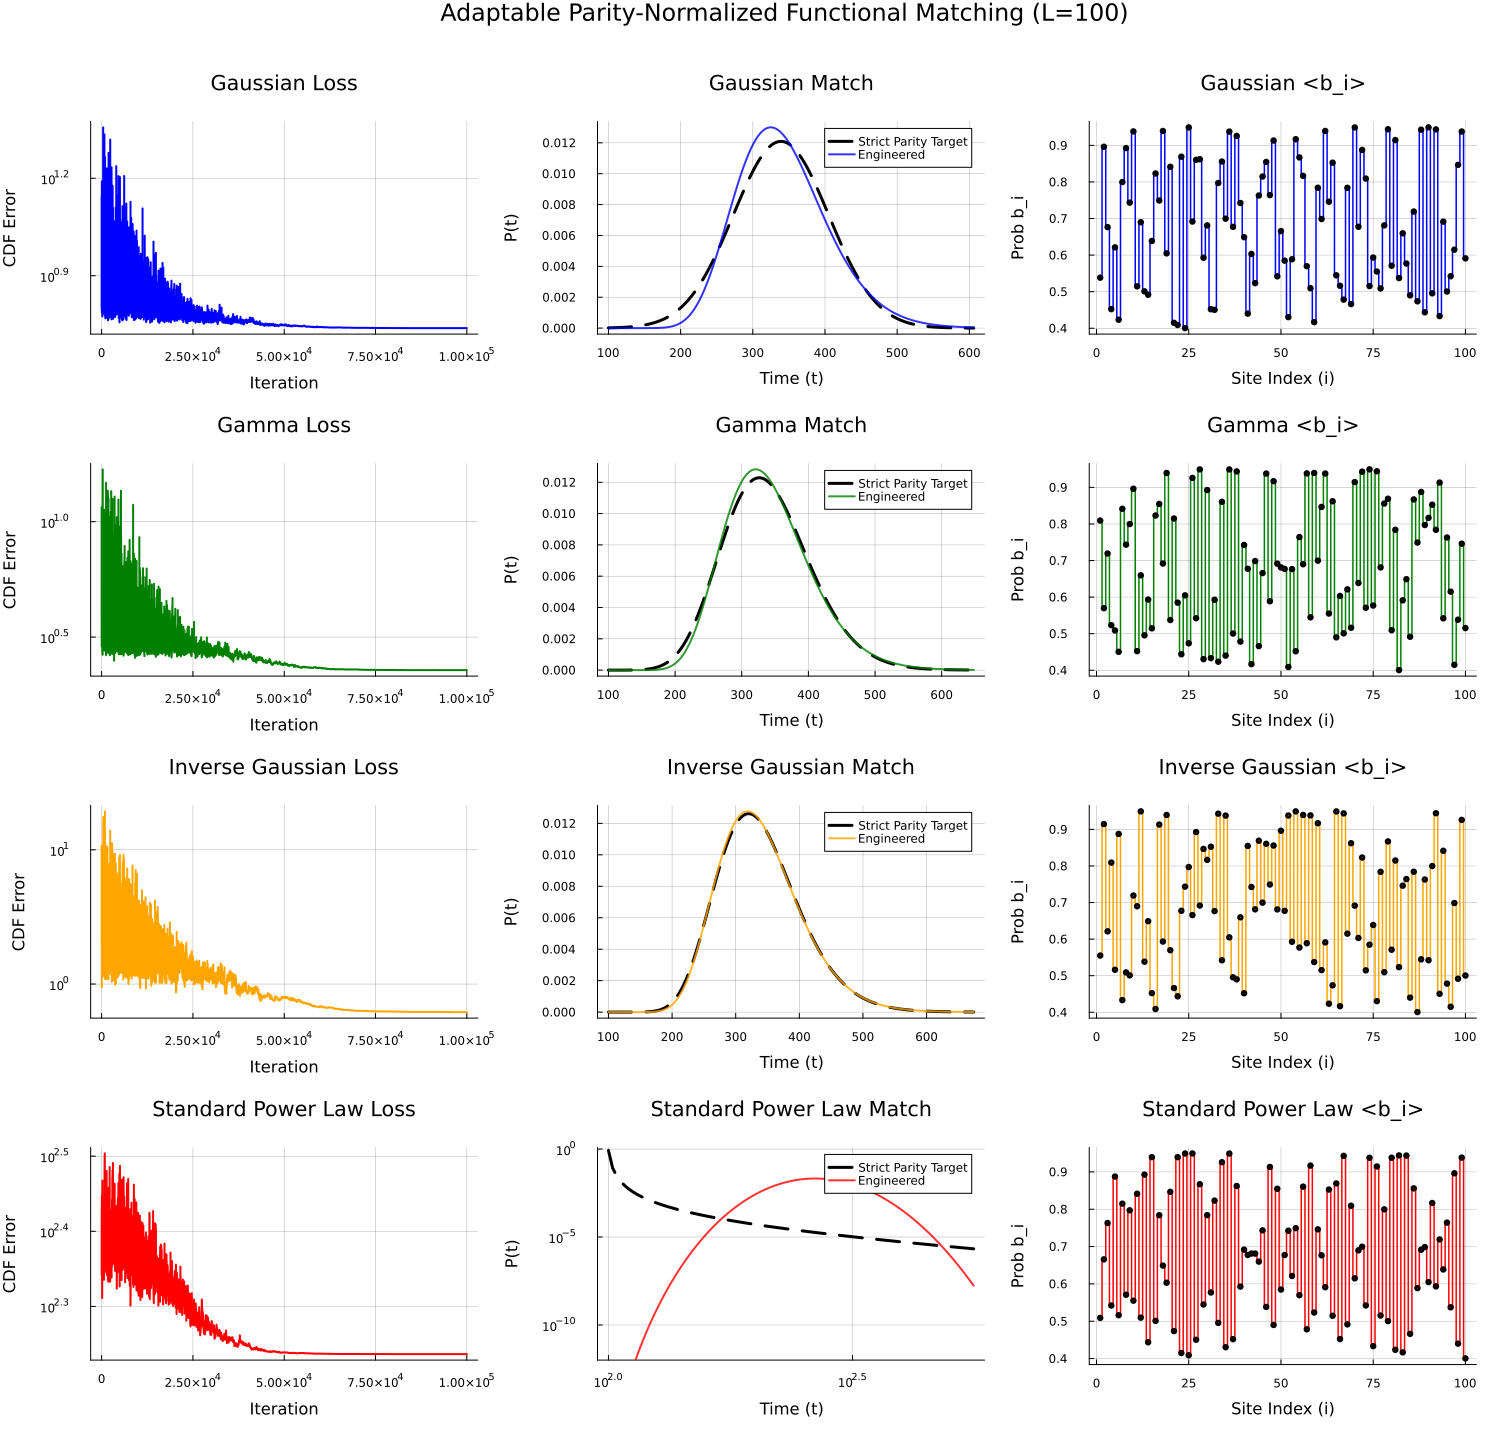

In [2]:
# ==============================================================================
# 3. Dynamic Adaptable Parity-Strict Target Generation
# ==============================================================================
Random.seed!(42)
L = 100
b_fixed_pool = rand(L) .* 0.55 .+ 0.40 

T_valid_mean, T_valid_var = calc_exact_moments_no_stay(shuffle(b_fixed_pool))
println("Extracted Natural Limits -> μ: $(round(Int, T_valid_mean)), σ²: $(@sprintf("%.2e", T_valid_var))")

mu = T_valid_mean
sigma2 = T_valid_var

# Moment-constrained targets
gauss_dist = Normal(mu, sqrt(sigma2))
gamma_dist = Gamma((mu^2) / sigma2, sigma2 / mu)
ig_dist = InverseGaussian(mu, (mu^3) / sigma2)

# Unconstrained standard power law
power_law_func(t) = (t - L + 1)^(-2.1)

# CORRECTED: Adaptive target generator aligned to absolute time
function generate_dynamic_parity_target(distribution_func; mass_threshold=0.9995, absolute_cap=25000)
    # 1. Pre-allocate full absolute time array (forces t < L to be exactly 0.0)
    raw_target = zeros(Float64, absolute_cap)
    
    # 2. Populate only valid parity steps from t=L onward
    for t in L:absolute_cap
        if (t - L) % 2 == 0
            raw_target[t] = distribution_func(t)
        end
    end
    
    # 3. Strictly normalize the entire array FIRST
    raw_target ./= sum(raw_target)
    
    # 4. Find where the *normalized* CDF crosses the threshold
    cdf = 0.0
    cutoff_t = L
    for t in L:absolute_cap
        cdf += raw_target[t]
        if cdf >= mass_threshold
            cutoff_t = t
            break
        end
    end
    
    # 5. Truncate exactly at the cutoff + 50 padding steps
    final_T_max = min(cutoff_t + 50, absolute_cap)
    final_target = raw_target[1:final_T_max]
    
    # Re-normalize just to be mathematically perfect after truncation
    final_target ./= sum(final_target)
    return final_target
end

targets = [
    ("Gaussian", generate_dynamic_parity_target(t -> pdf(gauss_dist, t)), :blue),
    ("Gamma", generate_dynamic_parity_target(t -> pdf(gamma_dist, t)), :green),
    ("Inverse Gaussian", generate_dynamic_parity_target(t -> pdf(ig_dist, t)), :orange),
    ("Standard Power Law", generate_dynamic_parity_target(power_law_func), :red)
]

# ==============================================================================
# 4. Execution, Normalization Testing & Plotting
# ==============================================================================
subplots = []
dir_pdf = figure_dir("annealing", "target", "pdf_engineering", "adaptable_parity")
mkpath(dir_pdf)

for (name, tgt_pdf, col) in targets
    T_max_dyn = length(tgt_pdf)
    println("\nOptimizing L=$L for $name (Adapted T_max = $T_max_dyn)...")
    
    b_best, pdf_res, loss_hist = anneal_cdf_global_ordering(b_fixed_pool, tgt_pdf, max_iter=100000)
    
    # === Explicit Normalization Test ===
    sum_tgt = sum(tgt_pdf)
    sum_res = sum(pdf_res)
    println("Normalization Test -> Target Sum: $(@sprintf("%.6f", sum_tgt)) | Engineered Sum: $(@sprintf("%.6f", sum_res))")
    
    p_loss = plot(1:length(loss_hist), loss_hist, yscale=:log10, lw=2, color=col,
                  title="$name Loss", xlabel="Iteration", ylabel="CDF Error", legend=false, gridalpha=0.3)
                  
    # Extract only the valid physical time steps for visualization
    valid_parity = (L:T_max_dyn)[1:2:end]
                  
    p_pdf = plot(valid_parity, tgt_pdf[valid_parity], lw=3, color=:black, ls=:dash, label="Strict Parity Target",
                 title="$name Match", xlabel="Time (t)", ylabel="P(t)", gridalpha=0.3)
    plot!(p_pdf, valid_parity, pdf_res[valid_parity], lw=2, color=col, alpha=0.8, label="Engineered")
    
    # Protect log-scale plotting against absolute zeros deep in the tail
    if name == "Standard Power Law"
        plot!(p_pdf, xscale=:log10, yscale=:log10, ylims=(1e-12, maximum(tgt_pdf)*1.5))
    end
    
    p_config = plot(1:L, b_best, st=:stepmid, lw=1.5, color=col,
                    title="$name <b_i>", xlabel="Site Index (i)", ylabel="Prob b_i", legend=false, gridalpha=0.3)
    scatter!(p_config, 1:L, b_best, color=col, ms=2)
    
    push!(subplots, p_loss, p_pdf, p_config)
end

p_grid = plot(subplots..., layout=(4, 3), size=(1500, 1440), margin=4Plots.mm,
              plot_title="Adaptable Parity-Normalized Functional Matching (L=$L)", plot_titlefontsize=16)

savefig(p_grid, joinpath(dir_pdf, "adaptable_parity_cdfs_final.pdf"))
display(p_grid)

In [ ]:
ENV["GKSwstype"] = "100"
using Distributions
using Plots
using Plots.PlotMeasures
using Printf
using Random
using Statistics

figures_dir = figure_dir("annealing", "target", "left_to_right")
mkpath(figures_dir)

# ==============================================================================
# 1. Exact Moments & Parity-Strict FPT Propagator (Left-to-Right: m0 = 1 -> L+1)
#    Aux reflecting site m = 0 (b_0 = 1), sites m = 1..L, absorbing at L+1
# ==============================================================================
function calc_exact_moments_no_stay(b::Vector{Float64})
    L = length(b)
    tau = Vector{Float64}(undef, L + 1)
    tau[1] = 1.0
    @inbounds for m in 1:L
        bm = b[m]
        tau[m + 1] = (1.0 + (1.0 - bm) * tau[m]) / bm
    end

    T = Vector{Float64}(undef, L + 1)
    acc = 0.0
    @inbounds for m in L:-1:0
        acc += tau[m + 1]
        T[m + 1] = acc
    end

    tau2 = Vector{Float64}(undef, L + 1)
    tau2[1] = 2.0 * T[1] - 1.0
    @inbounds for m in 1:L
        bm = b[m]
        tau2[m + 1] = ((2.0 * T[m + 1] - 1.0) + (1.0 - bm) * tau2[m]) / bm
    end

    mu  = T[2]
    var = sum(@view tau2[2:(L + 1)]) - mu^2
    if !isfinite(mu) || !isfinite(var) || var <= 0.0
        return Inf, Inf
    end
    return mu, var
end

function calc_fpt_pdf_m1!(
    pdf::Vector{Float64},
    p::Vector{Float64},
    p_next::Vector{Float64},
    b::Vector{Float64},
    d::Vector{Float64},
)
    L = length(b)
    T_max = length(pdf)

    fill!(p, 0.0)
    fill!(p_next, 0.0)
    fill!(pdf, 0.0)
    p[2] = 1.0 # index 1 = aux site m=0; index 2 = site m=1 (left start)

    @inbounds for t in 1:T_max
        is_odd_t  = (t & 1) == 1
        start_idx = is_odd_t ? 2 : 1
        tgt_start = is_odd_t ? 1 : 2

        for idx in tgt_start:2:(L + 1)
            p_next[idx] = 0.0
        end

        if t >= L && ((L + 1 - start_idx) & 1) == 0
            val_L = p[L + 1]
            pdf[t] = val_L * b[L]
            p_next[L] += val_L * d[L]
        end

        i0 = start_idx
        if i0 == 1
            p_next[2] += p[1]
            i0 = 3
        end

        hi_src = min(L, 1 + t)
        for idx in i0:2:hi_src
            val = p[idx]
            p_next[idx + 1] += val * b[idx - 1]
            p_next[idx - 1] += val * d[idx - 1]
        end

        p, p_next = p_next, p
    end

    return pdf
end

# ==============================================================================
# 2. Fast O(L) Pool Envelope Probe & Stage-1 Moment Pre-Annealer
# ==============================================================================
function probe_pool_envelope(b_pool::Vector{Float64}; n_steps::Int=12_000, seed::Int=42)
    rng = Xoshiro(seed)
    L = length(b_pool)

    # Minimize MFPT to find true fast limit
    b_fast = shuffle(rng, copy(b_pool))
    mu_fast, var_fast = calc_exact_moments_no_stay(b_fast)
    for _ in 1:n_steps
        i = rand(rng, 1:L)
        j = rand(rng, 1:(L - 1)); j >= i && (j += 1)
        b_fast[i], b_fast[j] = b_fast[j], b_fast[i]
        m, v = calc_exact_moments_no_stay(b_fast)
        if m < mu_fast
            mu_fast, var_fast = m, v
        else
            b_fast[i], b_fast[j] = b_fast[j], b_fast[i]
        end
    end

    # Minimize CV starting from fast config to find true CV floor
    b_cv = copy(b_fast)
    cv_min = sqrt(var_fast) / mu_fast
    for _ in 1:n_steps
        i = rand(rng, 1:L)
        j = rand(rng, 1:(L - 1)); j >= i && (j += 1)
        b_cv[i], b_cv[j] = b_cv[j], b_cv[i]
        m, v = calc_exact_moments_no_stay(b_cv)
        cv = isfinite(m) ? sqrt(v) / m : Inf
        if cv < cv_min
            cv_min = cv
        else
            b_cv[i], b_cv[j] = b_cv[j], b_cv[i]
        end
    end

    mu_slow, var_slow = calc_exact_moments_no_stay(sort(b_pool))
    return mu_fast, cv_min, mu_slow, (isfinite(mu_slow) ? sqrt(var_slow) / mu_slow : 1.0)
end

function preanneal_moments(
    b_pool::Vector{Float64},
    mu_tgt::Float64,
    cv_tgt::Float64;
    max_iter::Int=30_000,
    seed::Int=42,
)
    rng = Xoshiro(seed)
    L = length(b_pool)
    b = shuffle(rng, copy(b_pool))

    function mloss(bv::Vector{Float64})
        m, v = calc_exact_moments_no_stay(bv)
        !isfinite(m) && return 1e6
        cv = sqrt(v) / m
        return (log(m / mu_tgt))^2 + 2.0 * (cv - cv_tgt)^2
    end

    l_curr = mloss(b)
    b_best = copy(b)
    l_best = l_curr

    T0, T1 = 1.0, 1e-5
    cool = (T1 / T0)^(1.0 / max_iter)
    Temp = T0

    for _ in 1:max_iter
        i = rand(rng, 1:L)
        j = rand(rng, 1:(L - 1)); j >= i && (j += 1)
        b[i], b[j] = b[j], b[i]

        l_new = mloss(b)
        dL = l_new - l_curr
        if dL <= 0.0 || rand(rng) < exp(-dL / Temp)
            l_curr = l_new
            if l_curr < l_best
                l_best = l_curr
                copyto!(b_best, b)
            end
        else
            b[i], b[j] = b[j], b[i]
        end
        Temp *= cool
    end

    return b_best
end

# ==============================================================================
# 3. Parity-Strict Target Generator & Stage-2 Full-CDF Annealing
# ==============================================================================
function generate_dynamic_parity_target(
    dist_func::Function,
    L::Int;
    mass_threshold::Float64=0.995,
    absolute_cap::Int=60_000,
)
    raw = zeros(Float64, absolute_cap)
    for t in L:2:absolute_cap
        raw[t] = dist_func(Float64(t))
    end
    raw ./= sum(raw)

    cdf = 0.0
    cutoff_t = absolute_cap
    for t in L:2:absolute_cap
        cdf += raw[t]
        if cdf >= mass_threshold
            cutoff_t = t
            break
        end
    end

    if cutoff_t == absolute_cap
        @warn "Target reached absolute_cap = $absolute_cap before mass_threshold = $mass_threshold!"
    end

    T_max = min(cutoff_t + 50, absolute_cap)
    tgt = raw[1:T_max]
    tgt ./= sum(tgt)
    return tgt
end

function mean_cdf_l1_loss(pdf::Vector{Float64}, tgt_cdf::Vector{Float64}, L::Int)
    T_max = length(pdf)
    cdf_val = 0.0
    loss = 0.0
    n_pts = 0
    @inbounds for t in L:2:T_max
        cdf_val += pdf[t]
        loss += abs(cdf_val - tgt_cdf[t])
        n_pts += 1
    end
    return loss / n_pts
end

function anneal_cdf_m1(
    b_init::Vector{Float64},
    tgt_pdf::Vector{Float64};
    max_iter::Int=8_000,
    seed::Int=42,
)
    rng = Xoshiro(seed)
    L = length(b_init)
    T_max = length(tgt_pdf)
    tgt_cdf = cumsum(tgt_pdf)

    b_curr = copy(b_init)
    d_curr = 1.0 .- b_curr

    p_buf     = Vector{Float64}(undef, L + 1)
    pnext_buf = Vector{Float64}(undef, L + 1)
    pdf_curr  = Vector{Float64}(undef, T_max)
    pdf_prop  = Vector{Float64}(undef, T_max)

    calc_fpt_pdf_m1!(pdf_curr, p_buf, pnext_buf, b_curr, d_curr)
    loss_curr = mean_cdf_l1_loss(pdf_curr, tgt_cdf, L)

    b_best    = copy(b_curr)
    pdf_best  = copy(pdf_curr)
    loss_best = loss_curr

    # Warm-started cooling schedule (already in the right basin after Stage 1)
    T_start = max(0.35 * loss_curr, 5e-3)
    T_end   = 1e-6
    cool    = (T_end / T_start)^(1.0 / max_iter)
    Temp    = T_start

    loss_hist = Vector{Float64}(undef, max_iter)

    for iter in 1:max_iter
        if rand(rng) < 0.75
            i = rand(rng, 1:L)
            j = rand(rng, 1:(L - 1)); j >= i && (j += 1)
        else
            i = rand(rng, 1:(L - 1))
            j = i + 1
        end

        b_curr[i], b_curr[j] = b_curr[j], b_curr[i]
        d_curr[i], d_curr[j] = d_curr[j], d_curr[i]

        calc_fpt_pdf_m1!(pdf_prop, p_buf, pnext_buf, b_curr, d_curr)
        loss_prop = mean_cdf_l1_loss(pdf_prop, tgt_cdf, L)
        dL = loss_prop - loss_curr

        if dL <= 0.0 || rand(rng) < exp(-dL / Temp)
            loss_curr = loss_prop
            pdf_curr, pdf_prop = pdf_prop, pdf_curr
            if loss_curr < loss_best
                loss_best = loss_curr
                copyto!(b_best, b_curr)
                copyto!(pdf_best, pdf_curr)
            end
        else
            b_curr[i], b_curr[j] = b_curr[j], b_curr[i]
            d_curr[i], d_curr[j] = d_curr[j], d_curr[i]
        end

        loss_hist[iter] = max(loss_curr, 1e-12)
        Temp *= cool
    end

    return b_best, pdf_best, loss_hist
end

# ==============================================================================
# 4. Auto-Calibrate Four Reachable Shapes for ANY b_fixed_pool Range
# ==============================================================================
rng_pool = Xoshiro(42)
L = 60
b_fixed_pool = rand(rng_pool, L) .* 0.95 .+ 0.025 # Works for U(0.025, 0.975) or any other range

mu_fast, cv_min, mu_slow, cv_slow = probe_pool_envelope(b_fixed_pool)
@printf("True Pool Envelope (L=%d, m0=1) -> Fast: μ=%.1f (CV_min=%.3f) | Slow: μ=%.2e (CV=%.3f)\n",
        L, mu_fast, cv_min, mu_slow, cv_slow)

# Space 4 target CVs cleanly inside the pool's actual reachable cone [cv_min + 0.02, 0.86]
cv_lo = min(cv_min + 0.02, 0.55)
cv1, cv2, cv3, cv4 = collect(range(cv_lo, 0.86, length=4))
mu1, mu2, mu3, mu4 = mu_fast .* (1.15, 1.55, 2.20, 3.20)

# 1. Narrowest reachable bell (Normal if CV1 <= 0.28, else Gamma so mass stays strictly on t >= L)
dist1 = (cv1 <= 0.28) ? Normal(mu1, cv1 * mu1) : Gamma(1.0 / cv1^2, mu1 * cv1^2)
name1 = @sprintf("%s (CV=%.2f)", (cv1 <= 0.28 ? "Gaussian" : "Gamma"), cv1)

# 2. Inverse Gaussian (intermediate skew)
dist2 = InverseGaussian(mu2, mu2 / cv2^2)
name2 = @sprintf("Inverse Gaussian (CV=%.2f)", cv2)

# 3. Skewed LogNormal (sub-exponential bulk & heavy right tail)
sig_ln = sqrt(log(1.0 + cv3^2))
mu_ln  = log(mu3) - 0.5 * sig_ln^2
dist3  = LogNormal(mu_ln, sig_ln)
name3  = @sprintf("Skewed LogNormal (CV=%.2f)", cv3)

# 4. Shifted Exponential (single-barrier Kramers limit)
t0_exp    = max(Float64(L), (1.0 - cv4) * mu4)
scale_exp = mu4 - t0_exp
shifted_exp_pdf(t) = (t >= t0_exp) ? exp(-(t - t0_exp) / scale_exp) / scale_exp : 0.0
name4 = @sprintf("Shifted Exponential (CV=%.2f)", cv4)

targets = [
    (name1, mu1, cv1, generate_dynamic_parity_target(t -> pdf(dist1, t), L), :royalblue),
    (name2, mu2, cv2, generate_dynamic_parity_target(t -> pdf(dist2, t), L), :forestgreen),
    (name3, mu3, cv3, generate_dynamic_parity_target(t -> pdf(dist3, t), L), :darkorange),
    (name4, mu4, cv4, generate_dynamic_parity_target(shifted_exp_pdf, L),    :crimson),
]

# ==============================================================================
# 5. Two-Stage Optimize & Plot (Loss | FPT Match | Unclipped Weights b_i)
# ==============================================================================
subplots = []

for (idx, (name, mu_t, cv_t, tgt_pdf, col)) in enumerate(targets)
    T_max = length(tgt_pdf)
    valid_t = collect(L:2:T_max)

    t_sec = @elapsed begin
        b_init = preanneal_moments(b_fixed_pool, mu_t, cv_t; max_iter=30_000, seed=100 + idx)
        b_best, pdf_res, loss_hist = anneal_cdf_m1(b_init, tgt_pdf; max_iter=8_000, seed=200 + idx)
    end

    mu_eng, var_eng = calc_exact_moments_no_stay(b_best)
    cv_eng = sqrt(var_eng) / mu_eng
    ks_err = maximum(abs.(cumsum(pdf_res[valid_t]) .- cumsum(tgt_pdf[valid_t])))

    @printf("%-28s | T_max=%5d | Sum=%.4f | KS=%.4f | Eng μ=%6.1f, CV=%.3f | %.1fs\n",
            name, T_max, sum(pdf_res), ks_err, mu_eng, cv_eng, t_sec)

    p_loss = plot(1:length(loss_hist), loss_hist, yscale=:log10, lw=1.8, color=col,
                  title="$name Stage-2 Loss", xlabel="Iteration", ylabel="Mean CDF L1",
                  legend=false, gridalpha=0.3)

    p_pdf = plot(valid_t, tgt_pdf[valid_t], lw=3, color=:black, ls=:dash, label="Strict Parity Target",
                 title=@sprintf("%s (KS=%.3f, CV=%.2f)", name, ks_err, cv_eng),
                 xlabel="Time (t)", ylabel="P(t)", gridalpha=0.3, legend=:topright)
    plot!(p_pdf, valid_t, pdf_res[valid_t], lw=2.2, color=col, alpha=0.85, label="Engineered")

    p_config = plot(1:L, b_best, st=:stepmid, lw=1.5, color=col,
                    title="$name Weights b_i", xlabel="Site Index (i)", ylabel="Prob b_i",
                    ylims=(0.0, 1.0), legend=false, gridalpha=0.3)
    scatter!(p_config, 1:L, b_best, color=col, ms=2.5)
    hline!(p_config, [0.5], color=:black, ls=:dash, lw=1.2, alpha=0.6)

    push!(subplots, p_loss, p_pdf, p_config)
end

p_grid = plot(subplots..., layout=(4, 3), size=(1550, 1450), margin=4Plots.mm,
              plot_title="Left-to-Right FPT Shape Engineering (L=$L, m₀=1, Wide Pool b ∈ [0.025, 0.975])",
              plot_titlefontsize=15)

outpath = joinpath(figures_dir, "left_to_right_versatility_wide_L$(L).pdf")
savefig(p_grid, outpath)
display(p_grid)
println("\nSaved figure to ", outpath)

True Pool Envelope (L=60, m0=1) -> Fast: μ=4159.6 (CV_min=0.535) | Slow: μ=1.66e+19 (CV=1.000)
Gamma (CV=0.55)              | T_max=14240 | Sum=0.9921 | KS=0.0256 | Eng μ=4832.7, CV=0.556 | 8.2s
Inverse Gaussian (CV=0.65)   | T_max=24610 | Sum=0.9966 | KS=0.0044 | Eng μ=6355.2, CV=0.635 | 13.7s
Skewed LogNormal (CV=0.76)   | T_max=39820 | Sum=0.9979 | KS=0.0027 | Eng μ=8912.5, CV=0.689 | 22.5s
Shifted Exponential (CV=0.86) | T_max=53336 | Sum=0.9907 | KS=0.0265 | Eng μ=12960.8, CV=0.849 | 30.5s
